importing the libraries

In [258]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import seaborn as sns
from apyori import apriori

Importing the dataset : https://raw.githubusercontent.com/amankharwal/Website-data/master/Groceries_dataset.csv

In [259]:
df=pd.read_csv('https://raw.githubusercontent.com/amankharwal/Website-data/master/Groceries_dataset.csv')

In [260]:
df.head()

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


Data Analysis

In [261]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
dtypes: int64(1), object(2)
memory usage: 908.7+ KB


In [262]:
df.shape

(38765, 3)

In [263]:
df.isnull().sum()

Member_number      0
Date               0
itemDescription    0
dtype: int64

In [264]:
df.Date.value_counts()

Date
21-01-2015    96
21-07-2015    93
29-11-2015    92
08-08-2015    92
30-04-2015    91
              ..
29-06-2014    26
04-07-2014    24
16-03-2015    23
17-03-2015    23
01-09-2015    22
Name: count, Length: 728, dtype: int64

In [265]:
df.itemDescription.value_counts().nlargest(10)

itemDescription
whole milk          2502
other vegetables    1898
rolls/buns          1716
soda                1514
yogurt              1334
root vegetables     1071
tropical fruit      1032
bottled water        933
sausage              924
citrus fruit         812
Name: count, dtype: int64

In [266]:
df.itemDescription.value_counts().nsmallest(10)

itemDescription
kitchen utensil          1
preservation products    1
baby cosmetics           3
bags                     4
make up remover          5
toilet cleaner           5
frozen chicken           5
rubbing alcohol          5
salad dressing           6
whisky                   8
Name: count, dtype: int64

Text(0.5, 1.0, 'Top 10 selling items')

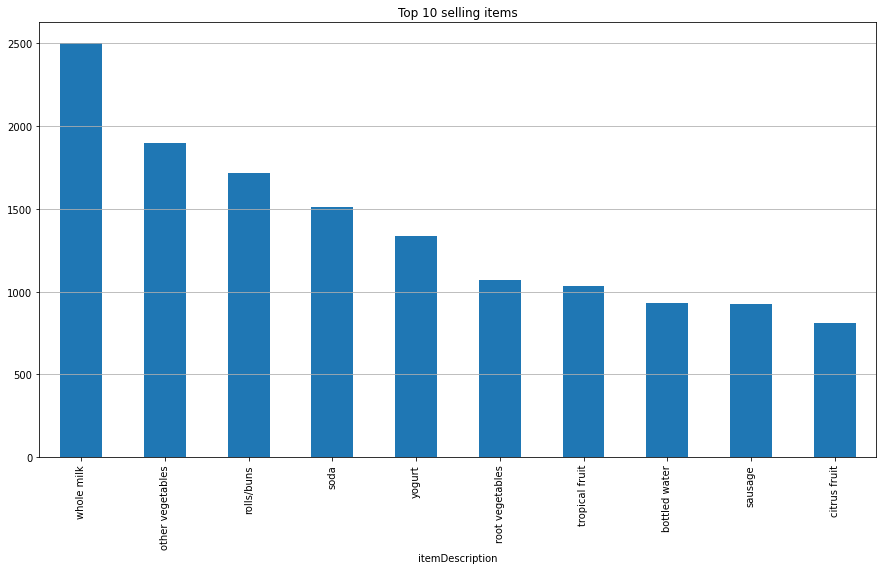

In [267]:
plt.figure(figsize=(15,8))
df.itemDescription.value_counts().nlargest(10).plot.bar()
plt.grid(axis='y')
plt.title("Top 10 selling items")

Text(0.5, 1.0, '10 Least Selling Items')

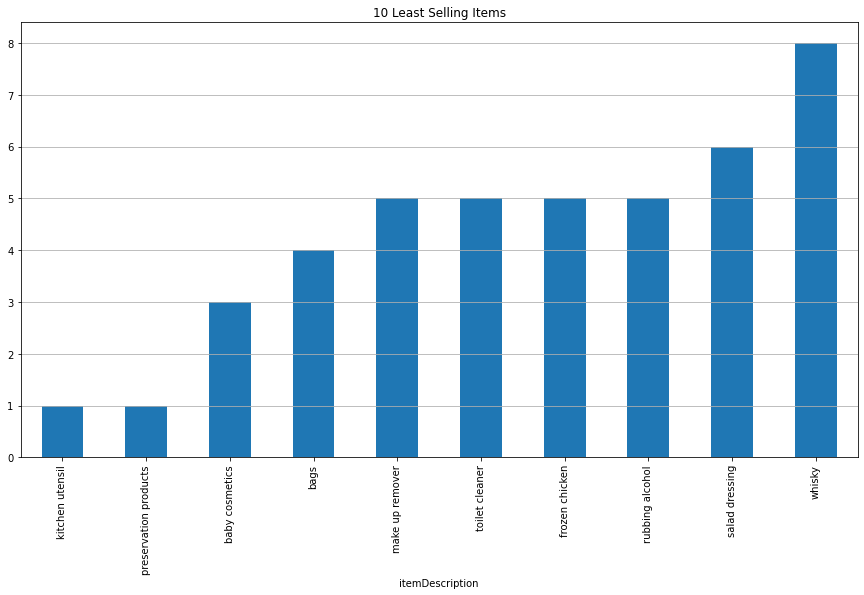

In [268]:
plt.figure(figsize=(15,8))
df.itemDescription.value_counts().nsmallest(10).plot.bar()
plt.grid(axis='y')
plt.title('10 Least Selling Items')

In [269]:
df.Member_number.value_counts().nlargest(10)

Member_number
3180    36
3737    33
3050    33
2051    33
2625    31
3915    31
2433    31
2271    31
3872    30
3289    29
Name: count, dtype: int64

Text(0.5, 1.0, 'Top 10 Frequent Customers')

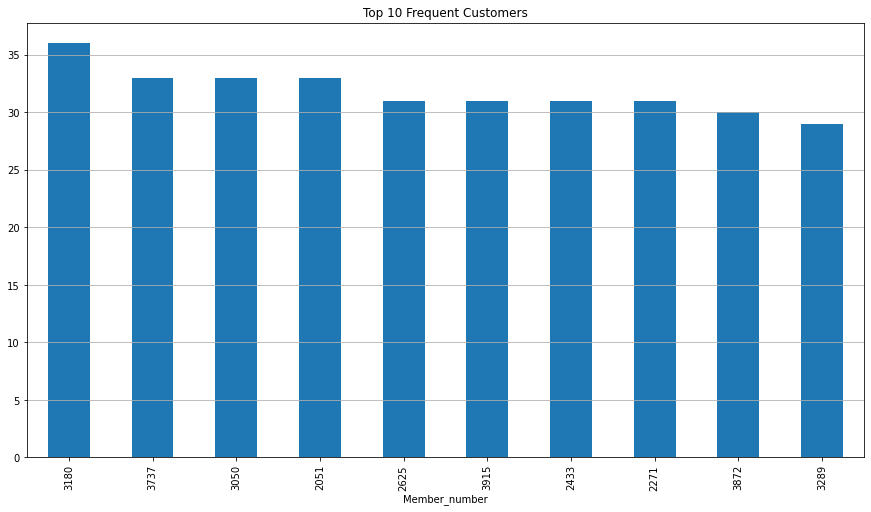

In [270]:
plt.figure(figsize=(15,8))
df.Member_number.value_counts().nlargest(10).plot.bar()
plt.grid(axis='y')
plt.title('Top 10 Frequent Customers')

In [271]:
df['Year']=pd.DatetimeIndex(df.Date).year
df['Month']=pd.DatetimeIndex(df.Date).month
df['Day']=pd.DatetimeIndex(df.Date).day


In [272]:
df.head()

,Member_number,Date,itemDescription,Year,Month,Day
0,1808,21-07-2015,tropical fruit,2015,7,21
1,2552,05-01-2015,whole milk,2015,5,1
2,2300,19-09-2015,pip fruit,2015,9,19
3,1187,12-12-2015,other vegetables,2015,12,12
4,3037,01-02-2015,whole milk,2015,1,2


In [273]:
df.Year.value_counts()

Year
2015    20488
2014    18277
Name: count, dtype: int64

In [274]:
df.Month.value_counts()

Month
8     3498
5     3335
1     3333
6     3316
3     3283
11    3273
7     3268
10    3218
4     3172
12    3074
2     3032
9     2963
Name: count, dtype: int64

In [275]:
df[df['Year']==2015][df['Month']==8]['Day'].value_counts().nlargest(5)

C:\Users\arunk\AppData\Local\Temp\ipykernel_4056\633015529.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df[df['Year']==2015][df['Month']==8]['Day'].value_counts().nlargest(5)


Day
8     92
20    83
21    83
15    82
18    82
Name: count, dtype: int64

Data Manipulation

In [276]:
df.head(2)

,Member_number,Date,itemDescription,Year,Month,Day
0,1808,21-07-2015,tropical fruit,2015,7,21
1,2552,05-01-2015,whole milk,2015,5,1


In [277]:
data=df.copy()
data.drop('Date',axis=1,inplace=True)

In [278]:
data=pd.get_dummies(data,dtype=int)

In [279]:
data.insert(df.columns.get_loc('Member_number')+1,'Date',df.Date)

In [280]:
data.head()

,Member_number,Date,Year,Month,Day,itemDescription_Instant food products,itemDescription_UHT-milk,itemDescription_abrasive cleaner,itemDescription_artif. sweetener,itemDescription_baby cosmetics,...,itemDescription_turkey,itemDescription_vinegar,itemDescription_waffles,itemDescription_whipped/sour cream,itemDescription_whisky,itemDescription_white bread,itemDescription_white wine,itemDescription_whole milk,itemDescription_yogurt,itemDescription_zwieback
0,1808,21-07-2015,2015,7,21,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2552,05-01-2015,2015,5,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,2300,19-09-2015,2015,9,19,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1187,12-12-2015,2015,12,12,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,3037,01-02-2015,2015,1,2,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [281]:
products=data.columns[5:]

In [282]:
data1=data.groupby(['Member_number','Date'])[products[:]].sum()

In [283]:
data1

itemDescription_Instant food products  \
Member_number Date                                                
1000          15-03-2015                                      0   
              24-06-2014                                      0   
              24-07-2015                                      0   
              25-11-2015                                      0   
              27-05-2015                                      0   
...                                                         ...   
4999          24-01-2015                                      0   
              26-12-2015                                      0   
5000          09-03-2014                                      0   
              10-02-2015                                      0   
              16-11-2014                                      0   

                          itemDescription_UHT-milk  \
Member_number Date                                   
1000          15-03-2015                         0   
              24-06-2014                         0   
              24-07-2015                         0   
              25-11-2015                         0   
              27-05-2015                         0   
...                                            ...   
4999          24-01-2015                         0   
              26-12-2015                         0   
5000          09-03-2014                         0   
              10-02-2015                         0   
              16-11-2014                         0   

                          itemDescription_abrasive cleaner  \
Member_number Date                                           
1000          15-03-2015                                 0   
              24-06-2014                                 0   
              24-07-2015                                 0   
              25-11-2015                                 0   
              27-05-2015                                 0   
...                                                    ...   
4999          24-01-2015                                 0   
              26-12-2015                                 0   
5000          09-03-2014                                 0   
              10-02-2015                                 0   
              16-11-2014                                 0   

                          itemDescription_artif. sweetener  \
Member_number Date                                           
1000          15-03-2015                                 0   
              24-06-2014                                 0   
              24-07-2015                                 0   
              25-11-2015                                 0   
              27-05-2015                                 0   
...                                                    ...   
4999          24-01-2015                                 0   
              26-12-2015                                 0   
5000          09-03-2014                                 0   
              10-02-2015                                 0   
              16-11-2014                                 0   

                          itemDescription_baby cosmetics  \
Member_number Date                                         
1000          15-03-2015                               0   
              24-06-2014                               0   
              24-07-2015                               0   
              25-11-2015                               0   
              27-05-2015                               0   
...                                                  ...   
4999          24-01-2015                               0   
              26-12-2015                               0   
5000          09-03-2014                               0   
              10-02-2015                               0   
              16-11-2014                               0   

                          itemDescription_bags  itemDesc

In [284]:
data1=data1.reset_index()[products]
data1

,itemDescription_Instant food products,itemDescription_UHT-milk,itemDescription_abrasive cleaner,itemDescription_artif. sweetener,itemDescription_baby cosmetics,itemDescription_bags,itemDescription_baking powder,itemDescription_bathroom cleaner,itemDescription_beef,itemDescription_berries,...,itemDescription_turkey,itemDescription_vinegar,itemDescription_waffles,itemDescription_whipped/sour cream,itemDescription_whisky,itemDescription_white bread,itemDescription_white wine,itemDescription_whole milk,itemDescription_yogurt,itemDescription_zwieback
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14958,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
14959,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
14960,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
14961,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [285]:
data1.values

array([[0, 0, 0, ..., 1, 1, 0],
       [0, 0, 0, ..., 1, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [286]:
def convert_to_list(data):
    for i in products:
        if data[i]>0:
            data[i]=i
    return data

In [287]:
data1=data1.apply(convert_to_list,axis=1)

C:\Users\arunk\AppData\Local\Temp\ipykernel_4056\501886440.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'itemDescription_sausage' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  data[i]=i
C:\Users\arunk\AppData\Local\Temp\ipykernel_4056\501886440.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'itemDescription_pastry' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  data[i]=i
C:\Users\arunk\AppData\Local\Temp\ipykernel_4056\501886440.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'itemDescription_canned beer' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  data[i]=i
C:\Users\arunk\AppData\Local\Temp\ipykernel_4056\501886440.py:4: FutureWarni

In [288]:
newdata=(data1.values)

In [289]:
newdata=[i[i!=0].tolist() for i in newdata if i[i!=0].tolist()]

In [290]:
newdata[:5]

[['itemDescription_sausage',
  'itemDescription_semi-finished bread',
  'itemDescription_whole milk',
  'itemDescription_yogurt'],
 ['itemDescription_pastry',
  'itemDescription_salty snack',
  'itemDescription_whole milk'],
 ['itemDescription_canned beer', 'itemDescription_misc. beverages'],
 ['itemDescription_hygiene articles', 'itemDescription_sausage'],
 ['itemDescription_pickled vegetables', 'itemDescription_soda']]

Apriori Implementation

In [291]:
for i in range(len(newdata)):
    for j in range(len(newdata[i])):
        newdata[i][j]=re.sub('itemDescription_','',newdata[i][j])

In [292]:
newdata[:10]

[['sausage', 'semi-finished bread', 'whole milk', 'yogurt'],
 ['pastry', 'salty snack', 'whole milk'],
 ['canned beer', 'misc. beverages'],
 ['hygiene articles', 'sausage'],
 ['pickled vegetables', 'soda'],
 ['curd', 'frankfurter'],
 ['rolls/buns', 'sausage', 'whole milk'],
 ['soda', 'whole milk'],
 ['beef', 'white bread'],
 ['frankfurter', 'soda', 'whipped/sour cream']]

In [293]:
association=apriori(transactions=newdata,
        min_support=0.0001,
        min_confidence=0.08,
        min_lift=3,
        max_length=2)
result=list(association)

In [294]:
itemset=[]
for i in range(len(result)):
    itemset.append(list(result[i][0]))

In [295]:
list(result[0][2][0][1])[0]

'frozen meals'

In [296]:
association_rule={}
for i in range(len(result)):
    association_rule[list(result[i][2][0][0])[0]]=list(result[i][2][0][1])[0]
association_rule

{'abrasive cleaner': 'meat',
 'bags': 'yogurt',
 'ready soups': 'white bread',
 'bathroom cleaner': 'waffles',
 'specialty fat': 'beef',
 'nut snack': 'sliced cheese',
 'soap': 'berries',
 'tidbits': 'coffee',
 'prosecco': 'waffles',
 'cookware': 'spices',
 'cocoa drinks': 'sausage',
 'canned fruit': 'specialty chocolate',
 'organic products': 'chicken',
 'fish': 'chocolate',
 'cleaner': 'meat',
 'cream': 'sausage',
 'nuts/prunes': 'white wine',
 'pudding powder': 'cream cheese ',
 'flower soil/fertilizer': 'curd',
 'decalcifier': 'whipped/sour cream',
 'rubbing alcohol': 'shopping bags',
 'honey': 'whipped/sour cream',
 'ketchup': 'frankfurter',
 'house keeping products': 'frozen vegetables',
 'liver loaf': 'white bread',
 'rum': 'ham',
 'popcorn': 'hamburger meat',
 'rice': 'napkins',
 'syrup': 'oil',
 'potato products': 'oil',
 'organic sausage': 'whipped/sour cream',
 'whisky': 'specialty chocolate',
 'soups': 'seasonal products',
 'sparkling wine': 'waffles',
 'specialty vegetable

In [297]:
for i in association_rule.keys():
    print(i,'->',association_rule[i],'\n')

abrasive cleaner -> meat 

bags -> yogurt 

ready soups -> white bread 

bathroom cleaner -> waffles 

specialty fat -> beef 

nut snack -> sliced cheese 

soap -> berries 

tidbits -> coffee 

prosecco -> waffles 

cookware -> spices 

cocoa drinks -> sausage 

canned fruit -> specialty chocolate 

organic products -> chicken 

fish -> chocolate 

cleaner -> meat 

cream -> sausage 

nuts/prunes -> white wine 

pudding powder -> cream cheese  

flower soil/fertilizer -> curd 

decalcifier -> whipped/sour cream 

rubbing alcohol -> shopping bags 

honey -> whipped/sour cream 

ketchup -> frankfurter 

house keeping products -> frozen vegetables 

liver loaf -> white bread 

rum -> ham 

popcorn -> hamburger meat 

rice -> napkins 

syrup -> oil 

potato products -> oil 

organic sausage -> whipped/sour cream 

whisky -> specialty chocolate 

soups -> seasonal products 

sparkling wine -> waffles 

specialty vegetables -> yogurt 

